# Hello, Numerai

**Click Runtime > Run all, then read through the notebook while it runs.** You can also run each cell one at a time as you follow along. The run may take a while. When it finishes, your browser downloads a `.pkl` model file to upload in step 2 of Tournament Basics.

Hello and welcome to the Numerai Data Science Tournament!

This notebook is designed to help you build your first machine learning model and start competing in the tournament.

In this notebook we will
1. Download and explore the Numerai dataset
2. Train your first machine learning model
3. Evaluate it with `NCORR` and benchmark contribution
4. Export your model as a .pkl file to upload in Tournament Basics

In [21]:
!python --version

Python 3.13.18


In [22]:
# Install dependencies
!pip install -q --upgrade numerapi pandas==2.3.1 pyarrow matplotlib lightgbm scikit-learn scipy

# Inline plots
%matplotlib inline

## 1. Dataset

The Numerai dataset is a tabular dataset that describes the stock market over time. Each row represents a stock on a particular date and includes a ticker.

The v6 dataset matches the v3.1 Signals dataset.

### Listing the datasets
Firstly, take a look at the files Numerai offers below:

In [23]:
# Initialize NumerAPI - the official Python API client for Numerai
from numerapi import NumerAPI
napi = NumerAPI()

# List the datasets and available versions
all_datasets = napi.list_datasets()
dataset_versions = list(set(d.split('/')[0] for d in all_datasets))
print("Available versions:\n", dataset_versions)

# Set data version to one of the latest datasets
DATA_VERSION = "v6.0"

# Print all files available for download for our version
current_version_files = [f for f in all_datasets if f.startswith(DATA_VERSION)]
print("Available", DATA_VERSION, "files:\n", current_version_files)

Available versions:
 ['v6.0']
Available v6.0 files:
 ['v6.0/features.json', 'v6.0/live.parquet', 'v6.0/live_benchmark_models.parquet', 'v6.0/live_example_preds.csv', 'v6.0/live_example_preds.parquet', 'v6.0/live_neutralizer.parquet', 'v6.0/train.parquet', 'v6.0/train_benchmark_models.parquet', 'v6.0/train_neutralizer.parquet', 'v6.0/validation.parquet', 'v6.0/validation_benchmark_models.parquet', 'v6.0/validation_example_preds.csv', 'v6.0/validation_example_preds.parquet', 'v6.0/validation_neutralizer.parquet']


### Downloading datasets

The `features.json` file contains metadata about the features and targets available for training.

Let's download it and take a look:

In [24]:
import json

# Download the feature metadata file
napi.download_dataset(f"{DATA_VERSION}/features.json")

# Read the metadata and display
feature_metadata = json.load(open(f"{DATA_VERSION}/features.json"))
for metadata in feature_metadata:
  print(metadata, len(feature_metadata[metadata]))

feature_sets 4
targets 24


### Feature Sets & Groups
As you can see there are many features and targets to choose from.

Instead of training on every feature, let's pick a subset to analyze.

Here are the starter sets Numerai offers:

- `small` contains a minimal subset of features

- `medium` contains a broader set of features

- `all` contains every feature

Let's compare their sizes:

In [25]:
feature_sets = feature_metadata["feature_sets"]
for feature_set_name in ["small", "medium", "all"]:
  print(feature_set_name, len(feature_sets[feature_set_name]))

small 101
medium 351
all 1040


We will use the `small` feature set.

For this notebook, we will train on a sample of the training data. Using more rows takes longer and requires more memory.

In [26]:
import pandas as pd

# Define our feature set. feature_country is text; this model uses numeric features.
feature_set = [feature for feature in feature_sets["small"] if feature != "feature_country"]
assert feature_set, "The small feature set has no numeric features"

# Download the training data - this will take a few minutes
napi.download_dataset(f"{DATA_VERSION}/train.parquet")

# Load the features and training target for every training date
train = pd.read_parquet(
    f"{DATA_VERSION}/train.parquet",
    columns=["numerai_ticker", "date", "target"] + feature_set,
).dropna(subset=["target"])
assert not train.empty, "The training file has no mature target rows"
last_train_date = pd.Timestamp(train["date"].max())
train = train.sample(n=min(200_000, len(train)), random_state=7)

### Training data

Each row represents a stock at a specific point in time:
- `numerai_ticker` identifies the stock
- `date` is the date
- `target` is a measure of future returns for that stock
- `features` describe the attributes of the stock for that date

In [27]:
train

,numerai_ticker,date,target,feature_intelligence_1,feature_intelligence_41,feature_charisma_2,feature_charisma_5,feature_charisma_7,feature_charisma_11,feature_charisma_13,...,feature_wisdom_23,feature_wisdom_41,feature_wisdom_53,feature_wisdom_67,feature_wisdom_75,feature_wisdom_78,feature_wisdom_96,feature_endurance_7,feature_endurance_13,feature_endurance_69
1530195,SSL GB,2009-07-10,0.75,1,0,4,4,1,1,3,...,0,1,3,0,1,2,4,2,4,0
794212,SSTI US,2006-10-06,0.50,0,4,2,2,2,2,1,...,2,2,2,3,2,1,2,0,2,0
3789159,SHW US,2017-06-02,0.50,4,0,0,4,3,3,2,...,1,1,3,1,3,1,3,4,2,1
3374500,OHL ES,2016-02-19,0.00,3,4,2,2,0,0,2,...,0,4,1,3,3,4,4,3,1,1
1771589,FM CA,2010-06-25,0.50,3,4,3,4,4,3,0,...,4,4,0,4,1,2,4,4,4,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2983933,FENG US,2014-11-28,0.50,0,4,3,3,3,3,4,...,3,3,1,1,3,1,3,1,1,4
402976,000270 KR,2005-03-11,0.25,2,4,0,3,3,4,1,...,2,2,2,4,2,3,2,4,1,1
230307,COHU US,2004-05-14,0.50,0,1,2,1,1,1,4,...,2,2,4,2,2,2,2,0,3,2
736843,9065 JP,2006-07-21,0.75,4,4,2,0,2,2,3,...,2,2,2,0,2,1,2,2,0,3


### Dates
The historical `date` values are one week apart.

Think of the rows within a `date` as a single example - throughout this notebook we score everything "per date". The rows per date below trace the size of Numerai's stock universe over time.

<Axes: title={'center': 'Number of rows per date'}, xlabel='Date'>

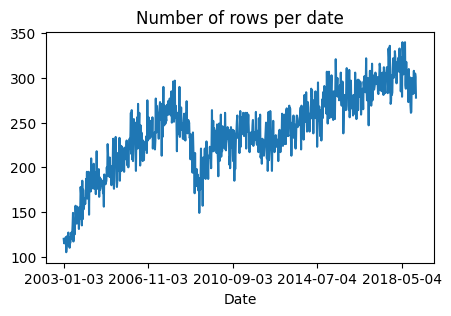

In [28]:
# Plot the number of rows per date
train.groupby("date").size().plot(
    title="Number of rows per date",
    figsize=(5, 3),
    xlabel="Date"
)

### Target
The `target` is a measure of "stock-specific" returns over the next 60 (business) days - returns not explained by well-known "factors" or broader trends in the market, country, or sector. For example, if Apple went up and the tech sector also went up, we only want to know if Apple went up more or less than the tech sector.
In this dataset, `target` is an alias for `target_jupiter_60`.

Target values are binned into 5 unequal bins: `0`, `0.25`, `0.5`, `0.75`, `1.0`. This heavy regularization avoids overfitting because the underlying values are extremely noisy.

<Axes: title={'center': 'Target'}, xlabel='Value', ylabel='Frequency'>

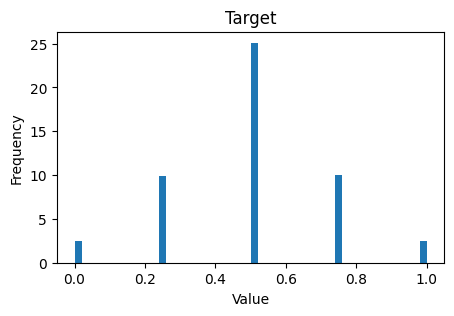

In [29]:
# Plot density histogram of the target
train["target"].plot(
  kind="hist",
  title="Target",
  figsize=(5, 3),
  xlabel="Value",
  density=True,
  bins=50
)

### Features
The `features` are quantitative attributes of each stock: fundamentals like P/E ratio, technical signals like RSI, market data like short interest, analyst ratings, and much more. Their definitions aren't important - Numerai includes them because we believe they help predict the `target`.

When available, feature values are binned into 5 equal-frequency integer bins: `0`, `1`, `2`, `3`, `4`. When a feature is missing for an era, that entire feature-era is filled with the middle bin `2`.

## 2. Modeling
Our task: predict the `target` using the `features`.

### Model training

You are free to use any tool or framework, but here we use LightGBM - a popular choice amongst tournament participants. While your model trains, watch this [video](https://www.youtube.com/watch?v=w8Y7hY05z7k) from our Chief Scientist MDO on why tree-based models work so well on tabular data.

In [30]:
# https://lightgbm.readthedocs.io/en/latest/pythonapi/lightgbm.LGBMRegressor.html
import lightgbm as lgb

model = lgb.LGBMRegressor(
  n_estimators=300,
  learning_rate=0.05,
  max_depth=5,
  num_leaves=2**5-1,
  colsample_bytree=0.1,
  verbosity=-1,
)

# This will take a few minutes per model 🍵
model.fit(
  train[feature_set],
  train["target"]
)

,max_depth,5
,learning_rate,0.05
,n_estimators,300
,colsample_bytree,0.1
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


### Validation predictions

Now let's make out-of-sample predictions on the validation dataset.

Validation is even bigger than train, so to stay within Colab's ~12GB of RAM we free the training data, filter rows during the parquet read, and predict one date at a time.

In [31]:
# Dates are 1 week apart, but the target looks 60 business days into the future,
# so we exclude validation dates within that horizon of our last training date.
validation_cutoff = last_train_date + pd.offsets.BDay(60)

# We are done training - free the training data to make room for validation
# (to re-train later, just re-run the cells above)
del train

# Load the validation data, filtering during the read so embargoed dates and
# the rows reserved for Numerai's test set never take up memory
napi.download_dataset(f"{DATA_VERSION}/validation.parquet")
validation = pd.read_parquet(
    f"{DATA_VERSION}/validation.parquet",
    columns=["numerai_ticker", "date", "target"] + feature_set,
    filters=[
        ("data_type", "==", "validation"),
        ("date", ">", validation_cutoff.strftime("%Y-%m-%d")),
    ],
).dropna(subset=["target"])

# Generate predictions one date at a time - predicting on the entire validation
# set in a single call would take several times more memory than Colab offers
# This will take a few minutes 🍵
predictions = []
for date, date_data in validation.groupby("date"):
    date_features = date_data[feature_set]
    predictions.append(pd.Series(model.predict(date_features), index=date_data.index))
validation["prediction"] = pd.concat(predictions)

# The features have done their job - keep only the columns we need for scoring
validation = validation[["numerai_ticker", "date", "prediction", "target"]]
scoring_dates = pd.to_datetime(validation["date"].unique()).strftime("%Y-%m-%d").tolist()
validation

v6.0/validation.parquet: 100%|██████████| 1.41G/1.41G [01:01<00:00, 22.9MB/s]


,numerai_ticker,date,prediction,target
0,000060 KR,2019-03-29,0.519638,0.25
1,000080 KR,2019-03-29,0.505835,0.75
2,000100 KR,2019-03-29,0.507694,1.00
3,000120 KR,2019-03-29,0.484961,0.25
4,000150 KR,2019-03-29,0.518151,0.75
...,...,...,...,...
2572695,ZURA US,2026-08-07,0.500820,0.50
2572696,ZURN CH,2026-08-07,0.497822,0.50
2572697,ZVRA US,2026-08-07,0.503798,0.50
2572698,ZWS US,2026-08-07,0.498840,0.25


,numerai_ticker,date,prediction,target
0,000060 KR,2019-03-29,0.519638,0.25
1,000080 KR,2019-03-29,0.505835,0.75
2,000100 KR,2019-03-29,0.507694,1.00
3,000120 KR,2019-03-29,0.484961,0.25
4,000150 KR,2019-03-29,0.518151,0.75
...,...,...,...,...
2572695,ZURA US,2026-08-07,0.500820,0.50
2572696,ZURN CH,2026-08-07,0.497822,0.50
2572697,ZVRA US,2026-08-07,0.503798,0.50
2572698,ZWS US,2026-08-07,0.498840,0.25


### Performance evaluation

Numerai's scores are designed to "align incentives": a model with good scores should help the hedge fund make good returns.

- `NCORR` (`neutral_correlation`): correlation with the target after removing exposure to the neutralizer matrix.

- Benchmark contribution (`neutral_contribution`): how much signal your model adds beyond a public benchmark, after neutralization. We use it here as an offline proxy for leaderboard NBMC.

We'll calculate both over the same validation dates.

In [32]:
# Install Numerai's open-source scoring tools
!pip install -q --no-deps numerai-tools==0.7.2

from numerai_tools.scoring import neutral_correlation, neutral_contribution

### NCORR: neutral correlation with the target

`NCORR` asks whether your predictions align with the target after removing exposure to the supplied neutralizers.

The neutralizer matrix has hundreds of columns for every validation row - several GB in total - so we never load it all at once. Each date's neutralizers are read straight from the parquet file when that date is scored, then discarded.

Always score each `date` independently - "per date" metrics are what matter, not one score across the whole validation set.

And yes, the scores are low: +/- 0.05 is normal in quantitative finance. This is why we call Numerai the "hardest data science tournament on the planet".

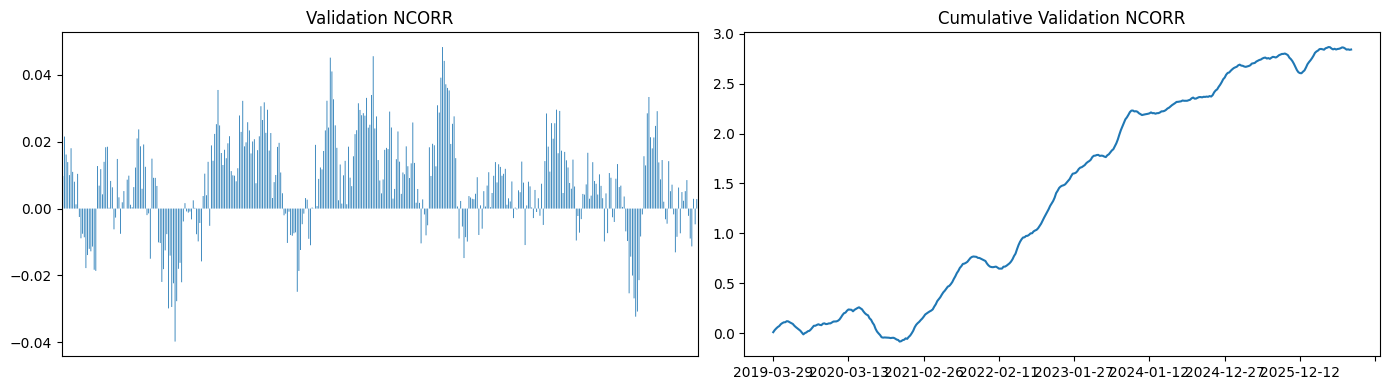

In [33]:
# Download the neutralizer matrix for the validation dates
napi.download_dataset(f"{DATA_VERSION}/validation_neutralizer.parquet")

# Open the file once and note which row groups hold each date. The file is written
# one date per row group, so a single date's rows can be read in a few milliseconds.
import pyarrow.parquet as pq
neutralizer_file = pq.ParquetFile(f"{DATA_VERSION}/validation_neutralizer.parquet")
neutralizer_columns = [column for column in neutralizer_file.schema_arrow.names if column.startswith("neutralizer_column_")]
assert neutralizer_columns, "The neutralizer file has no neutralizer columns"

date_column = neutralizer_file.schema_arrow.names.index("date")
row_group_dates = []  # (first date, last date) stored in each row group's metadata
for row_group in range(neutralizer_file.metadata.num_row_groups):
    date_stats = neutralizer_file.metadata.row_group(row_group).column(date_column).statistics
    row_group_dates.append((date_stats.min, date_stats.max))

def load_neutralizers(date: str) -> pd.DataFrame:
    """Read one date's neutralizer matrix from the parquet file, indexed by stock."""
    row_groups = [i for i, (first, last) in enumerate(row_group_dates) if first <= date <= last]
    neutralizers = neutralizer_file.read_row_groups(
        row_groups, columns=["numerai_ticker", "date"] + neutralizer_columns
    ).to_pandas()
    neutralizers = neutralizers[neutralizers["date"] == date].drop(columns="date").set_index("numerai_ticker")
    assert neutralizers.index.is_unique, f"Duplicate neutralizer rows on {date}"
    assert not neutralizers.isna().any().any(), f"Missing neutralizers on {date}"
    return neutralizers

# Compute NCORR on each date - only one date's neutralizers are in memory at a time
# This will take a few minutes 🍵
per_date_ncorr = {}
for date, date_data in validation.groupby("date"):
    date_data = date_data.set_index("numerai_ticker")
    per_date_ncorr[date] = neutral_correlation(
        date_data[["prediction"]], load_neutralizers(date), date_data["target"]
    )["prediction"]
per_date_ncorr = pd.Series(per_date_ncorr)

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
per_date_ncorr.plot(title="Validation NCORR", kind="bar", ax=axes[0], xticks=[], legend=False, snap=False)
per_date_ncorr.cumsum().plot(title="Cumulative Validation NCORR", kind="line", ax=axes[1], legend=False)
plt.tight_layout()
plt.show()

Cumulative `NCORR` is easier to read than the raw per-date scores - think of it as a rough backtest of your model's neutralized target alignment over the validation dates.

### NCORR summary metrics

A few summary metrics over the validation dates:
- **Mean**: average score.
- **Sharpe**: consistency - mean divided by standard deviation.
- **Max drawdown**: the largest peak-to-trough drop in cumulative score.

In [34]:
# Compute NCORR performance metrics
ncorr_mean = per_date_ncorr.mean()
ncorr_std = per_date_ncorr.std(ddof=0)
ncorr_sharpe = ncorr_mean / ncorr_std
ncorr_max_drawdown = (
    per_date_ncorr.cumsum().expanding(min_periods=1).max()
    - per_date_ncorr.cumsum()
).max()

pd.DataFrame({
    "mean": [ncorr_mean],
    "std": [ncorr_std],
    "sharpe": [ncorr_sharpe],
    "max_drawdown": [ncorr_max_drawdown]
}, index=["NCORR"]).T

,NCORR
mean,0.007383
std,0.014422
sharpe,0.511908
max_drawdown,0.343166


,NCORR
mean,0.007383
std,0.014422
sharpe,0.511908
max_drawdown,0.343166


### NMMC, NBMC, and benchmark contribution

`NMMC` measures how much signal your model adds beyond the Meta Model after neutralization. The Meta Model changes as participants submit new models, so a fixed historical backtest may not predict future NMMC.

`NBMC` is the leaderboard's benchmark-based contribution score. It uses the same `neutral_contribution` calculation as NMMC, but replaces the Meta Model with the benchmark reference for that round.

In this notebook, we use the same `neutral_contribution` calculation with one fixed public benchmark, `lgbm_jupiter_60`. This generic benchmark-contribution backtest does not reproduce either leaderboard score: the Meta Model and leaderboard benchmark references can differ from this fixed benchmark.

In [35]:
# Download and join public benchmark predictions for the validation dates
BENCHMARK_MODEL = "lgbm_jupiter_60"
napi.download_dataset(f"{DATA_VERSION}/validation_benchmark_models.parquet")
benchmarks = pd.read_parquet(
    f"{DATA_VERSION}/validation_benchmark_models.parquet",
    columns=["numerai_ticker", "date", BENCHMARK_MODEL],
    filters=[("date", "in", scoring_dates)],
)
validation = validation.merge(
    benchmarks, on=["numerai_ticker", "date"], how="left", validate="one_to_one"
)
del benchmarks

# Calculate contribution one date at a time, for dates covered by the benchmark
# This will take a few minutes 🍵
per_date_benchmark_contribution = {}
scorable = validation.dropna(subset=["prediction", "target", BENCHMARK_MODEL])
for date, date_data in scorable.groupby("date"):
    date_data = date_data.set_index("numerai_ticker")
    per_date_benchmark_contribution[date] = neutral_contribution(
        date_data[["prediction"]],
        date_data[BENCHMARK_MODEL],
        load_neutralizers(date),
        date_data["target"],
    )["prediction"]
per_date_benchmark_contribution = pd.Series(per_date_benchmark_contribution)
del scorable

### Benchmark contribution as an offline proxy for NMMC

A fixed public benchmark makes benchmark contribution a practical research objective: does your model add signal beyond a strong benchmark anyone can download? You can repeat this comparison while developing your model.

`NMMC` asks a similar question against the changing Meta Model. Benchmark contribution is therefore a directional offline proxy for NMMC, not the same numerical score. This notebook does not calculate historical NMMC against matching Meta Model predictions, so it does not plot a measured relationship between the two.

### Benchmark contribution validation performance

The fixed benchmark lets us estimate how much the model adds over the validation dates:

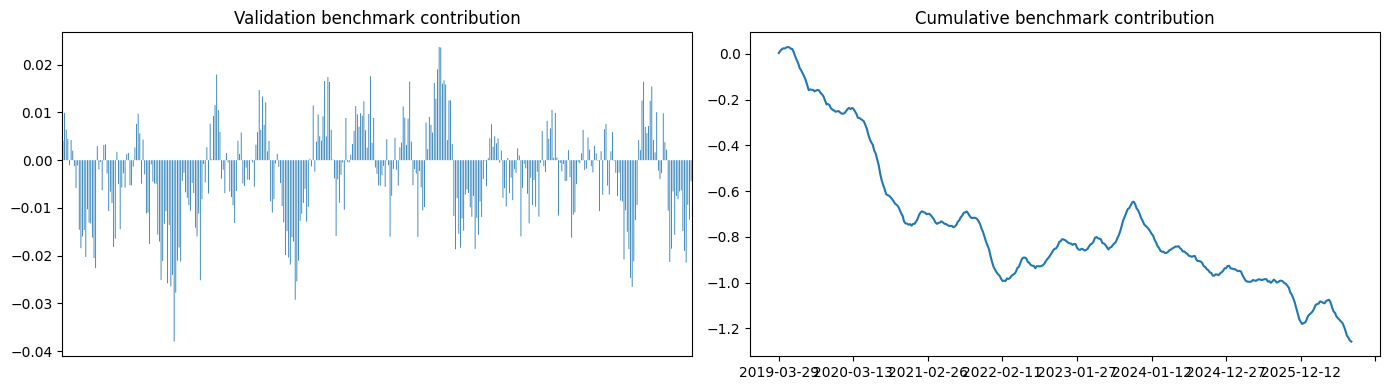

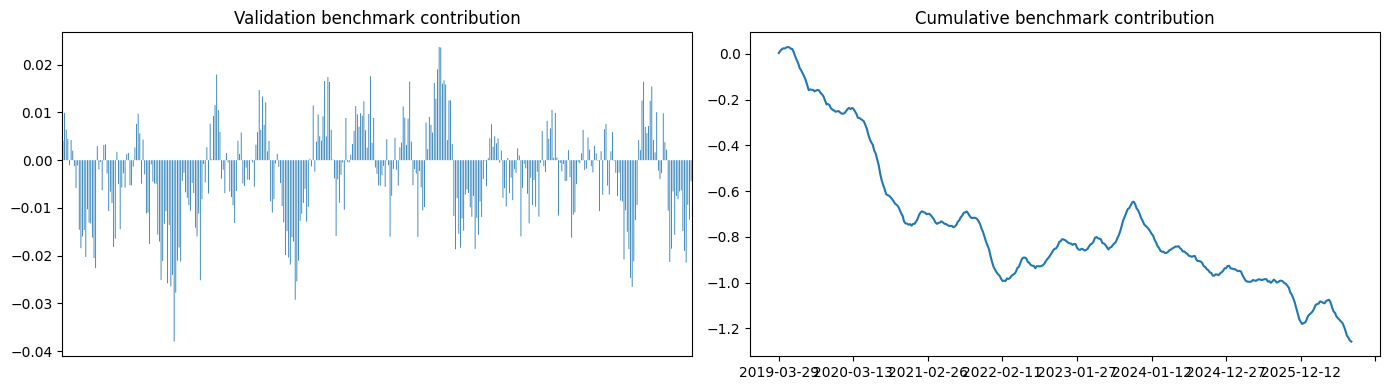

In [36]:
# Create a figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
per_date_benchmark_contribution.plot(title="Validation benchmark contribution", kind="bar", ax=axes[0], xticks=[], legend=False, snap=False)
per_date_benchmark_contribution.cumsum().plot(title="Cumulative benchmark contribution", kind="line", ax=axes[1], legend=False)
plt.tight_layout()
plt.show()

### Benchmark contribution summary metrics

The table below summarizes contribution over dates covered by the benchmark.

In [37]:
benchmark_summary = pd.DataFrame({
    "mean": [per_date_benchmark_contribution.mean()],
    "std": [per_date_benchmark_contribution.std(ddof=0)],
    "sharpe": [per_date_benchmark_contribution.mean() / per_date_benchmark_contribution.std(ddof=0)],
    "max_drawdown": [(per_date_benchmark_contribution.cumsum().cummax() - per_date_benchmark_contribution.cumsum()).max()],
}, index=["Benchmark contribution"]).T
benchmark_summary

,Benchmark contribution
mean,-0.003268
std,0.010075
sharpe,-0.324413
max_drawdown,1.288370


These metrics don't need to be amazing - we're just getting started. The next tutorials cover improving target prediction while adding unique signal beyond public benchmarks.

## 3. Export your model

To submit to Numerai, upload your model as a pickle file. Numerai runs it every round on the new live features and submits its predictions for you.

In [38]:
# Numerai loads your pickle and calls this function every round with the live features.
# Defining it here doesn't make predictions; it packages your trained model for upload.
def predict(live_features: pd.DataFrame, live_benchmark_models: pd.DataFrame) -> pd.DataFrame:
    live_predictions = model.predict(live_features[feature_set])
    submission = pd.Series(live_predictions, index=live_features.index).rank(pct=True)
    return submission.to_frame("prediction")

In [39]:
# Use the cloudpickle library to serialize your function, including the trained model
!pip install -q cloudpickle==3.1.1
import cloudpickle
p = cloudpickle.dumps(predict)
with open("hello_numerai.pkl", "wb") as f:
    f.write(p)

In [40]:
# Download file if running in Google Colab
try:
    from google.colab import files
    files.download('hello_numerai.pkl')
except ImportError:
    print('Model saved as hello_numerai.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

That's it! You now have a pickle file that is ready for upload.

Head back to the [Tournament Basics onboarding step](https://numer.ai/onboarding/tournament-basics) to upload `hello_numerai.pkl` in step 2. Numerai runs diagnostics on your uploaded model automatically, and you can review them in step 3.